# ANN vs. linear predictor

One held-out trajectory shown three ways: the ground-truth (corrected) heading, the heading predicted by the best baseline (free-slope circular / Möbius regression on airspeed direction, the best baseline in `tables.ipynb`), and the ANN's predicted heading. The Möbius model and the ANN are both evaluated on the paper's held-out split (seed 42, 33% test), so neither saw this trajectory in training.

The trajectory is chosen from held-out trajectories where the ANN is accurate and the Möbius baseline is not (see the candidate table).

In [1]:
import os, sys, random
import numpy as np
import pandas as pd
import keras
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.optimize import minimize
from sklearn.model_selection import GroupShuffleSplit
sys.path.insert(0, os.path.abspath('../utils'))
import fly_plot_lib_plot as fpl
from utils import (circular_distance, pull_out_individual_trajectories,
                   augment_with_time_delay_embedding, register_geodesic_loss)

random.seed(42)
data = pd.read_csv('../pipelinedata/05_final/all_wind_heading_and_trajectories_augmented_corrected_filtered_headx_heady.csv')
ids = data['trajec_objid'].unique()
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.33, random_state=42).split(np.zeros((len(ids), 1)), groups=ids))
train_ids, test_ids = set(ids[tr]), set(ids[te])
train_df = data[data['trajec_objid'].isin(train_ids)]
trajs = pull_out_individual_trajectories(data, min_traj_length=12)
test_trajs = [t.reset_index(drop=True) for t in trajs if t['trajec_objid'].iloc[0] in test_ids]
print(len(test_trajs), 'held-out trajectories')

I0000 00:00:1791843903.530668  506345 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791843903.531457  506345 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791843903.574201  506345 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791843904.708587  506345 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791843904.708951  506345 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Detected 3422 trajectories.


3340 trajectories with more than 12 timesteps.


1105 held-out trajectories


## Möbius baseline (airspeed direction)

$\hat\theta = \mu + 2\arctan(\beta\tan\frac{\theta_{air}-\nu}{2})$, fit on the training trajectories by minimising $\sum(1-\cos e)$.

In [2]:
def circ_mean(a): return np.arctan2(np.sin(a).mean(), np.cos(a).mean())
def mobius(x, mu, nu, lb): return mu + 2 * np.arctan(np.exp(lb) * np.tan((x - nu) / 2))

def fit_mobius(x, y):
    best = None
    for nu0 in np.linspace(0, 2 * np.pi, 8, endpoint=False):
        for lb0 in (-1.0, 0.0, 1.0, 2.0):
            r = minimize(lambda p: np.mean(1 - np.cos(y - mobius(x, *p))), [circ_mean(y - x), nu0, lb0],
                         method='Nelder-Mead', options=dict(xatol=1e-6, fatol=1e-10, maxiter=4000))
            if best is None or r.fun < best.fun: best = r
    return best.x

params = fit_mobius(train_df['airspeed_angle'].values, train_df['heading_angle'].values)
print(f'mu={params[0]:.3f}  nu={params[1]:.3f}  beta={np.exp(params[2]):.2f}')

mu=0.102  nu=0.086  beta=0.62


## ANN predictions

In [3]:
INPUTS = ['groundspeed', 'groundspeed_angle', 'airspeed', 'airspeed_angle']
KEEP = ['heading_angle_x', 'heading_angle_y', 'trajec_objid']
register_geodesic_loss()
ann = keras.models.load_model('../models/ann_wind_augmented_no_thrust_no_delay.keras')

def ann_heading(traj):
    emb = augment_with_time_delay_embedding([traj], wind_augment=False, wrap_angles=False, time_window=1,
                                            input_names=INPUTS, output_names=KEEP, direction='backward')
    p = ann.predict(emb.iloc[:, :len(INPUTS)].values, verbose=0)
    h = np.arctan2(p[:, 1], p[:, 0])
    return np.concatenate([np.full(len(traj) - len(h), h[0]), h])   # same alignment as plot_trajectory_with_predicted_heading

rows, preds = [], {}
for t in test_trajs:
    tid = t['trajec_objid'].iloc[0]
    truth = t['heading_angle'].values
    h_ann = ann_heading(t)
    h_mob = mobius(t['airspeed_angle'].values, *params)
    e_ann = np.degrees(circular_distance(truth, h_ann)); e_mob = np.degrees(circular_distance(truth, h_mob))
    dh = np.degrees(np.abs(circular_distance(truth[1:], truth[:-1])))
    preds[tid] = (h_mob, h_ann)
    rows.append({'trajec_objid': tid, 'n_frames': len(t), 'ann_err': np.median(e_ann), 'mobius_err': np.median(e_mob),
                 'gap': np.median(e_mob) - np.median(e_ann), 'heading_range_deg': np.degrees(np.ptp(np.unwrap(truth))),
                 'max_turn_deg_per_frame': dh.max()})
res = pd.DataFrame(rows).drop_duplicates('trajec_objid')

E0000 00:00:1791843916.447856  506345 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Choosing the example

Candidates: 30–250 frames (held-out trajectories are short, median 26 frames), ANN median error under 5°, Möbius median error over 15°, and a heading that actually changes (range over 60°) so the trajectory is not just a straight upwind flight. Ranked by the error gap.

In [4]:
print(res[['n_frames', 'ann_err', 'mobius_err', 'gap', 'heading_range_deg']].describe().round(1))
for nmin, ann_max, mob_min, rng_min in [(30, 4, 25, 90), (30, 5, 15, 90), (40, 5, 12, 60), (40, 6, 10, 45)]:
    c = res[res['n_frames'].between(nmin, 250) & (res['ann_err'] < ann_max) & (res['mobius_err'] > mob_min) & (res['heading_range_deg'] > rng_min)]
    print(f'n>={nmin}, ann<{ann_max}, mobius>{mob_min}, range>{rng_min}: {len(c)} trajectories')

       n_frames  ann_err  mobius_err     gap  heading_range_deg
count    1099.0   1099.0      1099.0  1099.0             1099.0
mean       33.7     18.0        20.6     2.6               71.0
std        30.1     33.8        29.6    16.1               73.8
min        13.0      0.5         0.5  -141.8                2.5
25%        19.0      2.7         4.8    -0.3               22.9
50%        26.0      5.4         8.5     2.0               53.5
75%        38.5     13.7        20.6     4.9               94.7
max       561.0    177.2       169.4   144.3             1087.5
n>=30, ann<4, mobius>25, range>90: 0 trajectories
n>=30, ann<5, mobius>15, range>90: 1 trajectories
n>=40, ann<5, mobius>12, range>60: 2 trajectories
n>=40, ann<6, mobius>10, range>45: 6 trajectories


In [5]:
cand = res[res['n_frames'].between(30, 250) & (res['ann_err'] < 5) & (res['mobius_err'] > 15)
           & (res['heading_range_deg'] > 60)].sort_values('gap', ascending=False)
display(cand.head(10).round(2))

,trajec_objid,n_frames,ann_err,mobius_err,gap,heading_range_deg,max_turn_deg_per_frame
380,20130327_193200_10522,35,3.06,24.37,21.31,138.9,33.4


In [6]:
TID = '20130327_193200_10522'   # top-ranked candidate above (the only one meeting every criterion)
print('example:', TID)

example: 20130327_193200_10522


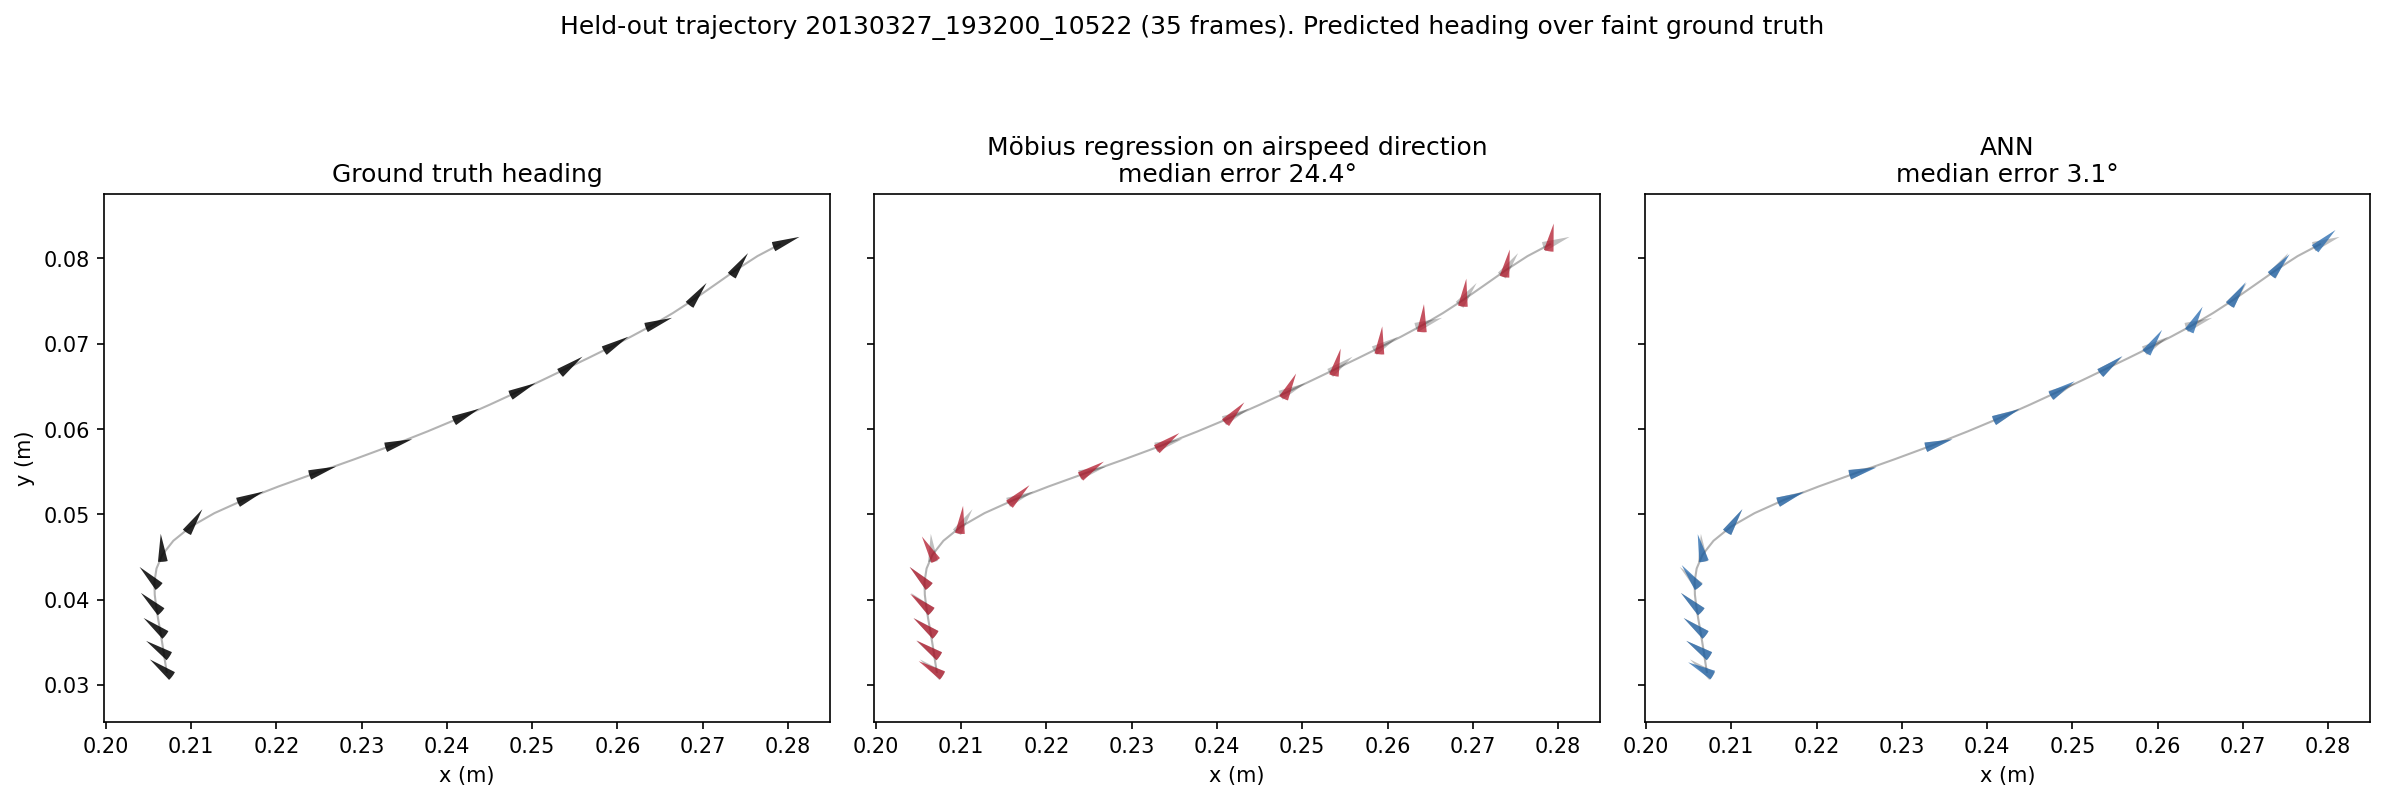

In [7]:
BLUE, RED, GREY = '#2166ac', '#b2182b', '#666666'

def draw_heading(ax, x, y, h, color, alpha, radius, every):
    cmap = mcolors.LinearSegmentedColormap.from_list('_c', [color, color])
    fpl.colorline_with_heading(ax, np.flip(x[::every]), np.flip(y[::every]), np.ones(len(x[::every])),
                               np.flip(h[::every]), nskip=0, size_radius=radius, deg=False, colormap=cmap,
                               center_point_size=0.0001, colornorm=[0, 1], show_centers=False,
                               size_angle=20, alpha=alpha, edgecolor='none')

t = next(t for t in test_trajs if t['trajec_objid'].iloc[0] == TID)
x, y, truth = t['position_x'].values, t['position_y'].values, t['heading_angle'].values
h_mob, h_ann = preds[TID]
r = res.set_index('trajec_objid').loc[TID]
extent = max(np.ptp(x), np.ptp(y)); radius = 0.045 * extent
every = max(2, len(t) // 28)
pad = 0.08 * extent

fig, axs = plt.subplots(1, 3, figsize=(16, 5.6), dpi=150, sharex=True, sharey=True)
panels = [('Ground truth heading', None, truth, GREY, None),
          ('Möbius regression on airspeed direction', h_mob, truth, RED, r['mobius_err']),
          ('ANN', h_ann, truth, BLUE, r['ann_err'])]
for ax, (title, h, tr_, color, err) in zip(axs, panels):
    ax.plot(x, y, color='0.7', lw=1, zorder=1)
    if h is None:
        draw_heading(ax, x, y, tr_, 'black', 0.85, radius, every)
    else:
        draw_heading(ax, x, y, tr_, 'black', 0.25, radius, every)   # faint ground truth underneath
        draw_heading(ax, x, y, h, color, 0.75, radius, every)
    ax.set_aspect('equal')
    ax.set_xlim(x.min() - pad, x.max() + pad); ax.set_ylim(y.min() - pad, y.max() + pad)
    ax.set_title(title if err is None else f'{title}\nmedian error {err:.1f}°')
    ax.set_xlabel('x (m)')
axs[0].set_ylabel('y (m)')
fig.suptitle(f'Held-out trajectory {TID} ({len(t)} frames). Predicted heading over faint ground truth', y=1.0)
fig.tight_layout()
os.makedirs('../figures', exist_ok=True)
fig.savefig('../figures/annvslinearpredictor.pdf', bbox_inches='tight')
fig.savefig('../figures/annvslinearpredictor.png', dpi=300, bbox_inches='tight')
plt.show()